# FIMN — ConvLSTM classifier for lensed transients

Runs end-to-end on the small sample in `demo_data/`.

**This is a smoke test on a downsampled training set of 256 samples, not a reproduction.** The demo only shows how the pipeline works.

To run on your own data, edit the **CONFIG** cell below — nothing else.

In [1]:
%reset -f

In [2]:
# ---- Choose a particular GPU in multi-GPU setup ----
import os
os.environ["CUDA_DEVICE_ORDER"]   = "PCI_BUS_ID"   # make numbering match nvidia-smi
os.environ["CUDA_VISIBLE_DEVICES"] = "0"          


In [3]:
# ---- TensorFlow C++ backend logging ----
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"        # suppress INFO, WARNING, ERROR
os.environ["TF_CPP_MAX_VLOG_LEVEL"] = "0"
os.environ["TF_CPP_MIN_VLOG_LEVEL"] = "0"

# ---- Other TF verbosity controls ----
os.environ["AUTOGRAPH_VERBOSITY"] = "0"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

# ---- Python warnings ----
import warnings
warnings.filterwarnings("ignore")

# ---- TensorFlow import ----
import tensorflow as tf

# ---- TensorFlow python logger ----
tf.get_logger().setLevel("ERROR")
tf.get_logger().propagate = False

# ---- Abseil logging (used internally by TF) ----
import absl.logging
absl.logging.set_verbosity(absl.logging.FATAL)

# ---- Autograph ----
tf.autograph.set_verbosity(0)

In [4]:


import numpy
import matplotlib.pyplot as plt
import numpy as np
import h5py


from tensorflow.keras import datasets, layers, models
import sys

from tensorflow.keras.layers import Conv2D, LSTM, Dense, Flatten, Reshape, TimeDistributed,MaxPooling2D, Input,BatchNormalization, Dropout,ConvLSTM2D, Concatenate,GlobalAveragePooling2D 
from tensorflow.keras.models import Sequential
import keras
import pickle
from tensorflow.keras.callbacks import ModelCheckpoint, Callback
import gc
import time
from collections import defaultdict
from tensorflow.keras.optimizers.schedules import ExponentialDecay
from tensorflow.keras.optimizers import Adam

print(tf.__version__)
print(tf.keras.__version__, keras.__version__)

2.12.0
2.12.0 2.12.0


In [5]:
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')

In [6]:
print("Num CPUs Available: ", len(tf.config.list_physical_devices('CPU')))
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))
print("GPUs Available: ", tf.config.list_physical_devices('GPU'))

Num CPUs Available:  1
Num GPUs Available:  1
GPUs Available:  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [7]:
gpus = tf.config.experimental.list_physical_devices('GPU')
tf.config.experimental.set_memory_growth(gpus[0], True)
logical_gpus = tf.config.experimental.list_logical_devices('GPU')
print(len(gpus), "Physical GPUs,", len(logical_gpus), "Logical GPUs")

1 Physical GPUs, 1 Logical GPUs


In [8]:
def create_dir(path):
    os.makedirs(path, exist_ok=True)
def min_max(x):
    x = np.asarray(x)
    return np.min(x), np.max(x)

filters=['g','r','i','z']
def show_images(data, time_indices,time_vals=[],vmin=0.0, vmax=1.0,savename=False):
    num_time_indices = len(time_indices)
    fig, axes = plt.subplots(nrows=4, ncols=num_time_indices, figsize=(12, 8))
    
    for i, idx in enumerate(time_indices):
        for j in range(4):  # 4 filters
            axes[j, i].imshow(data[:, :, :, j][idx], cmap='gray', vmin=vmin, vmax=vmax)  # Accessing the 4th dimension

            if j == 0:
                if len(time_vals):
                    axes[j, i].set_title(f"Time {time_vals[idx]} d (ts={idx})")
                else:
                    axes[j, i].set_title(f"Time Stamp {idx}")
            if i== 0:
                axes[j, i].set_ylabel(f"{filters[j]}")
                axes[j, i].tick_params(axis='both', which='both', bottom=False, top=False, left=False, right=False,
                                        labelbottom=False, labelleft=False)
            else:
                axes[j, i].axis('off')

    plt.tight_layout()
    if savename:
        plt.savefig('%s.pdf'%(savename))
    plt.show()

In [9]:
# =============================================================================
#  CONFIG  --  the only cell you need to edit to run on a different dataset
# =============================================================================

# ---- data ----
DATA_DIR  = "./demo_data/FIMN_pad0_demo768/"   # root containing Train/ Val/ Test/
IMG_SHAPE = (59, 59, 4)                        # (height, width, n_bands)

# ---- training ----
BATCH_SIZE = 32
NHOLD      = 4        # bad epochs before rolling back to the best model
SEED       = 1

# ---- optimiser / LR schedule (unchanged from the full-dataset run) ----
ILR         = 1e-4
DECAY_STEPS = 630 * 4
DECAY_RATE  = 0.98

# ---- run / resume ----
RUN_ID       = 0        # bump for a new run so outputs land in a fresh folder
LOAD_MODE    = "ckpt"   # "keras" or "ckpt"
RESUME_DIR   = "./"     # folder holding checkpoints/ and metrics_file.txt
RESUME_EPOCH = 0        # only resumes if those files exist, else starts fresh

# ---- demo mode --------------------------------------------------------------
# Set DEMO_DATA = False and the notebook runs exactly as the production job did:
# one epoch = one pass over the data, no BatchNorm recalibration. Every deviation
# the demo needs is set in this one if-block and nowhere else in the notebook.
#
# Why a small dataset needs it: BatchNorm keeps a second set of statistics used
# only at inference, updated once per optimiser *step* as an EMA (momentum 0.99,
# several hundred steps to converge from its initial variance of 1.0). The true
# activation variance here is ~3e-4, so until the EMA converges validation
# divides activations by a number ~50x too large, every layer collapses to its
# bias, and the network becomes a constant function of its input: val_accuracy
# freezes at the majority-class rate while train_accuracy climbs normally.
# The full dataset has ~1000 steps per epoch, so this resolves inside epoch 1 and
# is never seen.
DEMO_DATA = True

if DEMO_DATA:
    STEPS_PER_EPOCH = 128    # cycle the small training set so one epoch holds
                             # enough optimiser steps
    RECALIBRATE_BN  = 32     # training batches used to recompute BatchNorm's
                             # inference statistics before each validation pass;
                             # touches moving_mean / moving_variance only --
                             # no weights, no gradients, no architecture change
    NEPOCH          = 30
else:
    STEPS_PER_EPOCH = None   # one epoch = one pass over the data
    RECALIBRATE_BN  = 0      # off: the EMA converges on its own at full size
    NEPOCH          = 200


In [10]:
# -----------------------------------------------------------------------------
# Build the demo dataset from the full (private) dataset.  Disabled by default.
# Reads the original read-only; writes only into DATA_DIR.
# -----------------------------------------------------------------------------
REGENERATE_DEMO_DATA = True

ORIG_DIR   = ("/gpfs1/satadru/find_lens_LSTM2/stored_sets/Not_normalized/26Feb26/"
              "FIMN_clip-1_min_subtract_pad0/")
DEMO_DTYPE = np.float16   # lossless: the model computes in float16 anyway

if REGENERATE_DEMO_DATA:
    rng = np.random.default_rng(142)

    # ---- demo-set construction (only used by the regeneration cell below) --------
    # The paper's val/test sets carry realistic priors (~10% / ~7% positive). At demo
    # size that makes val_accuracy unreadable -- a blind model already scores 0.90.
    # The demo sets are class-balanced instead, so the base rate is 0.50 and any real
    # learning is visible. Training data is ~50/50 in the paper too.
    N_DEMO         = {"Train": 768, "Val": 256, "Test": 256}
    DEMO_BALANCED  = True
    for split, n in N_DEMO.items():
        s, d = os.path.join(ORIG_DIR, split), os.path.join(DATA_DIR, split)
        create_dir(d)

        img = np.load(f"{s}/All_bands_arranged_{split}_sam_images_pad0.npy", mmap_mode="r")
        lab = np.load(f"{s}/All_{split}_sam_labels.npy",                     mmap_mode="r")
        epo = np.load(f"{s}/All_bands_arranged_{split}_sam_epochs.npy",      mmap_mode="r")
        det = np.loadtxt(f"{s}/label_and_details_{split}.txt", dtype=str)

        if DEMO_BALANCED:                      # equal positives / negatives
            y   = np.asarray(lab[:, 0])        # the label is constant along time
            pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
            idxs = np.sort(np.concatenate([rng.choice(pos, n // 2,     replace=False),
                                           rng.choice(neg, n - n // 2, replace=False)]))
        else:
            idxs = np.sort(rng.choice(len(img), n, replace=False))

        np.save(f"{d}/idxs_{split}.npy", idxs)
        # images are compressed (~3.9x) to keep every file under GitHub's 100 MiB
        np.savez_compressed(f"{d}/All_bands_arranged_{split}_sam_images_pad0.npz",
                            np.asarray(img[idxs]).astype(DEMO_DTYPE))
        np.save(f"{d}/All_{split}_sam_labels.npy",                np.asarray(lab[idxs]))
        np.save(f"{d}/All_bands_arranged_{split}_sam_epochs.npy", np.asarray(epo[idxs]))
        np.savetxt(f"{d}/label_and_details_{split}.txt", det[idxs], fmt="%s")

        print(f"{split:5s}: saved {len(idxs)} samples, pos_frac={np.asarray(lab[idxs]).mean():.3f}")

Train: saved 768 samples, pos_frac=0.500
Val  : saved 256 samples, pos_frac=0.500
Test : saved 256 samples, pos_frac=0.500


In [11]:
def load_array(stem):
    """Load <stem>.npy memory-mapped, or <stem>.npz if the array shipped compressed."""
    if os.path.exists(stem + '.npy'):
        return np.load(stem + '.npy', mmap_mode='r')
    return np.load(stem + '.npz')['arr_0']

def load_npy_setfile(file_path,phrase):
    image_data=load_array(file_path+'All_bands_arranged_'+phrase+'_sam_images_pad0')
    labels=load_array(file_path+'All_'+phrase+'_sam_labels')
    epoch_data=load_array(file_path+'All_bands_arranged_'+phrase+'_sam_epochs')
    return image_data,labels,epoch_data

def load_individual_npy_files(data_dir, prefix):
    data_var = []
    label_var = []
    epoch_var = []
    
    num_samples = len([f for f in os.listdir(data_dir) if f.startswith(f'{prefix}_sam_images') and f.endswith('.npy')])

    for i in range(num_samples):
        data_var.append(np.load(os.path.join(data_dir, f'{prefix}_sam_images{i}.npy')))
        epoch_var.append(np.load(os.path.join(data_dir, f'{prefix}_sam_epochs{i}.npy')))
        label_var.append(np.load(os.path.join(data_dir, f'{prefix}_sam_labels{i}.npy')))

    return data_var, label_var, epoch_var

def load_details(details_file):
    details = np.loadtxt(details_file, dtype=str)
    multi_label, set_ids = details[:,0].astype(int),details[:,1]
    return multi_label, set_ids


store_sets_dir = DATA_DIR

train_dir = store_sets_dir + 'Train/'
val_dir = store_sets_dir + 'Val/'
test_dir = store_sets_dir + 'Test/'

train_data_var, train_label_var, train_epoch = load_npy_setfile(train_dir, 'Train')
train_multi_label,train_ids = load_details(os.path.join(train_dir, 'label_and_details_Train.txt'))

val_data_var, val_label_var, val_epoch = load_npy_setfile(val_dir, 'Val')
val_multi_label,val_ids = load_details(os.path.join(val_dir, 'label_and_details_Val.txt'))
    
test_data_var, test_label_var, test_epoch = load_npy_setfile(test_dir, 'Test')
test_multi_label,test_ids = load_details(os.path.join(test_dir, 'label_and_details_Test.txt'))

In [12]:
datasets = [
    ("Train", train_data_var, train_label_var, train_epoch, train_multi_label, train_ids),
    ("Val",   val_data_var,   val_label_var,   val_epoch,   val_multi_label,   val_ids),
    ("Test",   test_data_var,   test_label_var,   test_epoch,   test_multi_label,   test_ids),
]

for name, data, label, epoch, multi_label, ids in datasets:
    print(f"\n{name}")
    print("-" * 60)
    for var_name, var in [
        ("data", data),
        ("label", label),
        ("epoch", epoch),
        ("multi_label", multi_label),
        ("ids", ids),
    ]:
        shape = getattr(var, "shape", f"len={len(var)}")
        dtype = getattr(var, "dtype", type(var).__name__)
        print(f"{var_name:12s} shape = {shape!s:20s} dtype = {dtype}")


Train
------------------------------------------------------------
data         shape = (768, 14, 59, 59, 4) dtype = float16
label        shape = (768, 14)            dtype = int64
epoch        shape = (768, 14)            dtype = float64
multi_label  shape = (768,)               dtype = int64
ids          shape = (768,)               dtype = <U20

Val
------------------------------------------------------------
data         shape = (256, 14, 59, 59, 4) dtype = float16
label        shape = (256, 14)            dtype = int64
epoch        shape = (256, 14)            dtype = float64
multi_label  shape = (256,)               dtype = int64
ids          shape = (256,)               dtype = <U20

Test
------------------------------------------------------------
data         shape = (256, 14, 59, 59, 4) dtype = float16
label        shape = (256, 14)            dtype = int64
epoch        shape = (256, 14)            dtype = float64
multi_label  shape = (256,)               dtype = int64
ids  

In [13]:
#check if normalised:
def check_data_min_max(data, multi_label, idxs=np.arange(20)):
    print(f"{'Idx':>4} {'Shape':>18} {'Label':>8} {'Min':>8} {'Max':>8} {'1st Min':>10} {'1st Max':>10}")
    print("-" * 72)

    for ii in idxs:
        mn, mx = np.min(data[ii]), np.max(data[ii])
        mn0, mx0 = np.min(data[ii][0]), np.max(data[ii][0])

        print(
            f"{ii:4d} {str(data[ii].shape):>18} {multi_label[ii]:8} "
            f"{mn:8.3f} {mx:8.3f} {mn0:10.3f} {mx0:10.3f}"
        )

check_data_min_max(train_data_var, train_multi_label)

 Idx              Shape    Label      Min      Max    1st Min    1st Max
------------------------------------------------------------------------
   0    (14, 59, 59, 4)        2    0.000    1.124      0.000      1.000
   1    (14, 59, 59, 4)        2    0.000    2.617      0.000      1.000
   2    (14, 59, 59, 4)      -21    0.000    2.393      0.000      1.000
   3    (14, 59, 59, 4)        2    0.000    3.832      0.000      1.000
   4    (14, 59, 59, 4)      -21    0.000    1.444      0.000      1.000
   5    (14, 59, 59, 4)      -31    0.000    1.188      0.000      1.000
   6    (14, 59, 59, 4)      -21    0.000    2.027      0.000      1.000
   7    (14, 59, 59, 4)        2    0.000    1.874      0.000      1.000
   8    (14, 59, 59, 4)      -31    0.000    1.091      0.000      1.000
   9    (14, 59, 59, 4)        4    0.000    4.340      0.000      1.000
  10    (14, 59, 59, 4)        2    0.000    5.203      0.000      1.000
  11    (14, 59, 59, 4)      -21    0.000    1.619 

In [14]:
def check_min_max(A):
    print(A.shape,min_max(A))

id_check=37
print('variable epoch training: sample size=',len(train_data_var),len(train_label_var))
print('variable epoch training: random sample shape=',train_data_var[id_check].shape,train_label_var[id_check].shape,len(train_epoch[id_check]))
print('variable epoch validation: sample size=',len(val_data_var),len(val_label_var))
print('variable epoch validation: random sample shape=',val_data_var[id_check].shape,val_label_var[id_check].shape,len(val_epoch[id_check]))

id_check=99
check_min_max(train_data_var[id_check])

variable epoch training: sample size= 768 768
variable epoch training: random sample shape= (14, 59, 59, 4) (14,) 14
variable epoch validation: sample size= 256 256
variable epoch validation: random sample shape= (14, 59, 59, 4) (14,) 14
(14, 59, 59, 4) (0.0, 1.779)


In [15]:
label_dict={1:'Mocks',0:'Transients',-11:"LRGs",-12:"Spirals",-21:"SNIa in LRGs",-22:"SNIa in Spirals"}
def check_set_composition(multi_labels, if_return=False):
    unique_elements = np.sort(np.unique(multi_labels, return_index=False))[::-1]
    
    Ntot=len(multi_labels)
    indices_of_unique_elements=[np.where(multi_labels == element)[0] for element in unique_elements]
    Nunique_elements=np.array([len(dum) for dum in indices_of_unique_elements])
    Ncheck=np.sum(Nunique_elements)
    if Ncheck==Ntot:
        print(f"Total: {Ntot}: \n unique elements={unique_elements} \n nos = {Nunique_elements} :: ratios={Nunique_elements/Ntot}")
        
    else:
        raise ValueError(f"Ncheck!=Ntot:: {Ncheck,Ntot,Nunique_elements}")
    if if_return:
        return unique_elements, indices_of_unique_elements

In [16]:
check_set_composition(train_multi_label)

Total: 768: 
 unique elements=[  4   2   0 -21 -22 -31] 
 nos = [195 189  72 128  66 118] :: ratios=[0.25390625 0.24609375 0.09375    0.16666667 0.0859375  0.15364583]


label= [1 1 1 1 1 1 1 1 1 1 1 1 1 1] : Nt =  14 : multi-label =  2 : lsr catalog id =  32199 
Normalized epoch values =  [0.         0.02757113 0.05751347 0.1009843  0.43293481 0.47750759
 0.51680498 0.86016361 0.91050491 0.95908719 0.99000063 1.07903561
 1.11088338 1.1204928 ]


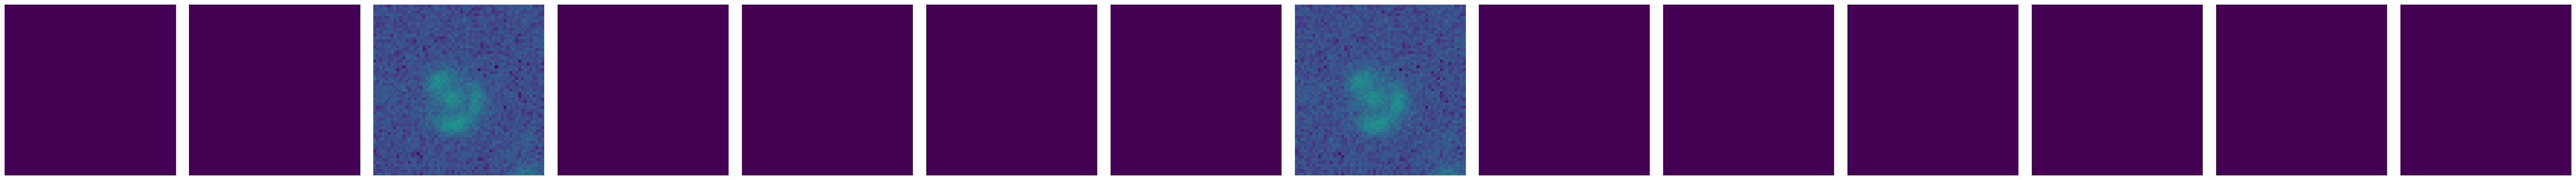

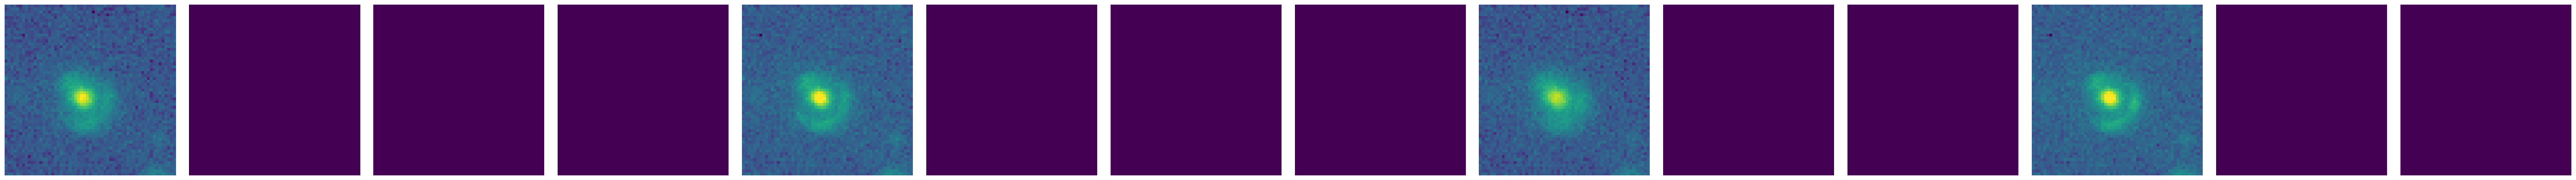

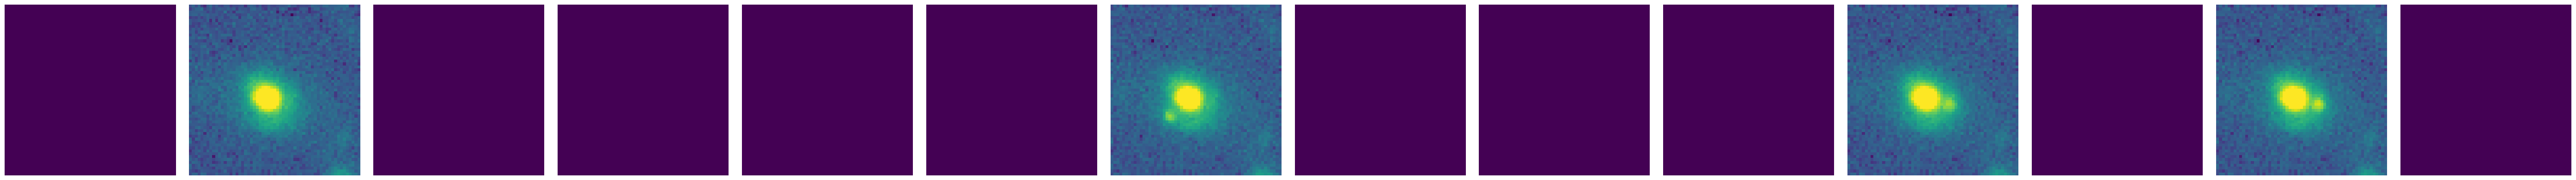

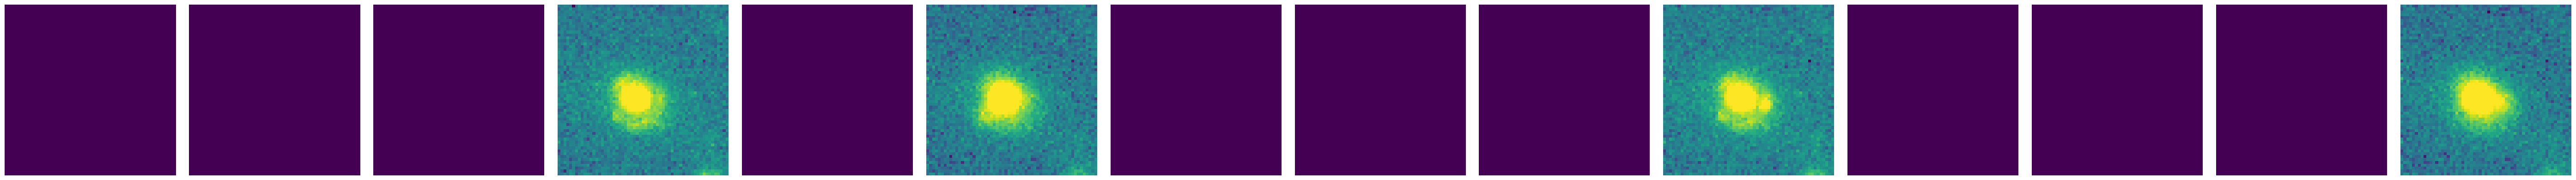

In [17]:
def plot_panels(array,vmin=None, vmax=None):
    N,NB = array.shape[0],array.shape[-1]
    for ib in range(NB):
        fig, axes = plt.subplots(1, N, figsize=(N * 4, 4))
        if N == 1:
            axes = [axes]
        for i in range(N):
            ax = axes[i]
            if vmin is not None:
                ax.imshow(array[i,:,:,ib], cmap='viridis', vmin=vmin, vmax=vmax)
            else:
                ax.imshow(array[i,:,:,ib], cmap='viridis')
            ax.axis('off')
        plt.tight_layout()
        plt.show()

def check_sys(id,data,label,multi_label1,_epochs,idss,vmin,vmax):
    print("label=",label[id],": Nt = ",len(label[id]),": multi-label = ",multi_label1[id], ": lsr catalog id = ",idss[id],
          '\nNormalized epoch values = ',_epochs[id])
    plot_panels((data[id]),vmin,vmax)

id=1
check_sys(id,train_data_var, train_label_var,train_multi_label,train_epoch,train_ids,0,1)

In [18]:
def bucket_data_by_length2(data, labels, additional_data):
    buckets = defaultdict(list)
    for d, l, a in zip(data, labels, additional_data):
        buckets[len(d)].append((d, l, a))
    return buckets

def data_generator2(data, labels, additional_data, max_batch_size=32, multi_labels=None):
    buckets = bucket_data_by_length2(data, labels, additional_data)
    
    def generator():
        bucket_keys = list(buckets.keys())
        for length in bucket_keys:
            bucket = buckets[length]
            for start_idx in range(0, len(bucket), max_batch_size):
                end_idx = min(start_idx + max_batch_size, len(bucket))
                batch = bucket[start_idx:end_idx]
                batch_data = np.array([item[0] for item in batch])
                batch_labels = np.array([item[1] for item in batch])
                batch_additional_data = np.array([item[2] for item in batch])
                # Ensure additional data has shape (batch_size, time_steps, 1)
                batch_additional_data = np.expand_dims(batch_additional_data, axis=-1)
                if multi_labels is not None:
                    batch_multi_labels = np.array(multi_labels[start_idx:end_idx])
                    yield (batch_data, batch_additional_data), batch_labels, batch_multi_labels
                else:
                    yield (batch_data, batch_additional_data), batch_labels
                
    return generator

max_batch_size = BATCH_SIZE
train_generator2 = data_generator2(train_data_var, train_label_var, train_epoch, max_batch_size)
val_generator2 = data_generator2(val_data_var, val_label_var, val_epoch, max_batch_size)

train_ds2 = tf.data.Dataset.from_generator(
    generator=train_generator2,
    output_types=((tf.float32, tf.float32), tf.int32),
    output_shapes=((tf.TensorShape([None, None, *IMG_SHAPE]), tf.TensorShape([None, None, 1])), tf.TensorShape([None, None]))
)

val_ds2 = tf.data.Dataset.from_generator(
    generator=val_generator2,
    output_types=((tf.float32, tf.float32), tf.int32),
    output_shapes=((tf.TensorShape([None, None, *IMG_SHAPE]), tf.TensorShape([None, None, 1])), tf.TensorShape([None, None]))
)
# Cycle the training set (see CONFIG); validation stays finite, one clean pass.
if STEPS_PER_EPOCH is not None:
    train_ds2 = train_ds2.repeat()

In [19]:
# Identical to the full-dataset run. Small-data fixes belong in the pipeline.
def get_model(show_model=False):

    image_input = Input(shape=(None, *IMG_SHAPE), name="image_input")
    time_input  = Input(shape=(None,1), name="additional_input")

    # ----- image branch -----
    x = ConvLSTM2D(32,(3,3),padding="valid",activation="relu",return_sequences=True)(image_input)
    x = BatchNormalization()(x)
    x = TimeDistributed(MaxPooling2D((2,2)))(x)

    x = ConvLSTM2D(64,(3,3),padding="same",activation="relu",return_sequences=True)(x)
    x = BatchNormalization()(x)
    x = TimeDistributed(MaxPooling2D((2,2)))(x)

    x = ConvLSTM2D(64,(3,3),padding="same",activation="relu",return_sequences=True)(x)
    x = BatchNormalization()(x)
    x = TimeDistributed(MaxPooling2D((2,2)))(x)

    x = TimeDistributed(GlobalAveragePooling2D())(x)
    x = TimeDistributed(Dense(128,activation="relu"))(x)

    # ----- time branch -----
    t = LSTM(32, return_sequences=True)(time_input)

    # ----- fusion -----
    x = Concatenate()([x,t])

    x = TimeDistributed(Dense(64,activation="relu",dtype="float32"))(x)
    out = TimeDistributed(Dense(1,activation="sigmoid",dtype="float32"))(x)

    model = tf.keras.Model([image_input,time_input], out)

    ilr, ds, dr = ILR, DECAY_STEPS, DECAY_RATE
    lr_schedule = ExponentialDecay(
        initial_learning_rate=ilr,
        decay_steps=ds,
        decay_rate=dr,
        staircase=False
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr_schedule),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    if show_model: model.summary()

    return model,ilr,ds,dr

In [20]:
import tensorflow.keras.backend as K
import shutil
import glob

def mv(src, dst_dir):
    import os
    dst = os.path.join(dst_dir, os.path.basename(src))
    os.replace(src, dst)

def get_stat(history):
    train_loss = history.history['loss'][0]
    train_accuracy = history.history.get('accuracy', [0])[0]
    val_loss = history.history['val_loss'][0]
    val_accuracy = history.history.get('val_accuracy', [0])[0]
    return train_loss,train_accuracy,val_loss,val_accuracy


def save_model_and_stat(temp_epochs,temp_stat):
    for epoch1, temp_stat1 in zip(temp_epochs,temp_stat):

        with open(metrics_file, 'a') as f:
            f.write(f"{epoch1}\t{temp_stat1[0]:.4f}\t{temp_stat1[1]:.4f}\t{temp_stat1[2]:.4f}\t{temp_stat1[3]:.4f}\n")

        # move keras model
        mv(out_dir_adap + f"temp_models/model_epoch_{epoch1}.keras", out_dir_adap)
        # move checkpoint files
        ckpt_files = glob.glob(out_dir_adap + f"temp_models/ckpt2-{epoch1}*")

        if len(ckpt_files) >= 2:
            for fpath in ckpt_files:
                mv(fpath, CHECKPOINT_DIR)


class RecalibrateBN(tf.keras.callbacks.Callback):
    """Recompute BatchNorm inference statistics from the training data before each
    validation pass. Touches only moving_mean / moving_variance -- no gradients,
    no weights, no change to the model itself. See RECALIBRATE_BN in CONFIG."""
    def __init__(self, ds, steps):
        super().__init__()
        self.ds, self.steps = ds, steps

    def on_test_begin(self, logs=None):
        bns = [l for l in self.model.layers if isinstance(l, BatchNormalization)]
        if not bns or not self.steps:
            return
        saved = [l.momentum for l in bns]
        for l in bns:                       # first batch overwrites the stale value
            l.momentum = 0.0
        for i, (x, _) in enumerate(self.ds.take(self.steps)):
            self.model(x, training=True)    # updates moving stats only
            if i == 0:
                for l in bns:               # remaining batches smooth it
                    l.momentum = 0.9
        for l, m in zip(bns, saved):
            l.momentum = m


def model_adjust(model):
    opt = model.optimizer
    if hasattr(opt, "inner_optimizer"):
        opt = opt.inner_optimizer
    old = opt._learning_rate
    step=opt.iterations.numpy()
    print("\n step=",step,"\n")
    old_lr0=old(0).numpy()
    new_lr_fac = 10**np.random.uniform(-2, 2)
    new_lr0 = np.float32(np.clip(old_lr0 * new_lr_fac, 1e-8, 1e-2))
    new_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
        initial_learning_rate=new_lr0,
        decay_steps=old.decay_steps,
        decay_rate=old.decay_rate,
        staircase=old.staircase
    )
    print("=="*20,f"\n⚠️🔧 adjusting model ... \nCurrent - LR0 = {old_lr0:.4e} : LR = {old(step).numpy():.4e}",
    f"\nNew - LR0 = {new_lr0:.4e} :   LR = {new_schedule(step).numpy():.4e} ... with a factor={new_lr_fac:.4e}")

    opt._learning_rate = new_schedule
    return model


In [21]:
indir = RESUME_DIR

initial_epoch = RESUME_EPOCH

tf.keras.utils.set_random_seed(SEED)      # seeds python random, numpy, and tf


try:

    if LOAD_MODE == "keras":
        model_adap = keras.models.load_model(indir + f"model_epoch_{initial_epoch}.keras")

    elif LOAD_MODE == "ckpt":
        model_adap,ilr,ds,dr = get_model()
        model_adap(next(iter(train_ds2))[0], training=False)

        ckpt = tf.train.Checkpoint(model=model_adap, optimizer=model_adap.optimizer)
        ckpt.restore(indir + f"checkpoints/ckpt2-{initial_epoch}")

    loss_acc_data=np.loadtxt(indir+"metrics_file.txt")
    print(loss_acc_data.shape)

    best_val_loss=loss_acc_data[initial_epoch-1][3]
    print(f"initial model loaded successfully: best val_loss={best_val_loss}")

    out_dir_adap=indir

except Exception as e:
    print(f"no run to resume from ({type(e).__name__}: {e}) -> starting fresh")


    model_adap,ilr,ds,dr=get_model(show_model=True)

    initial_epoch=0
    best_val_loss=np.Inf

    out_dir_adap='./Results_run%d_batch%d_ilr%e_ds%d_dr%.2f/'%(RUN_ID,max_batch_size,ilr,ds,dr)


create_dir(out_dir_adap+'temp_models/')
create_dir(out_dir_adap+'checkpoints/')

print("initial_epoch=",initial_epoch,"best val_loss=",best_val_loss)

no run to resume from (NotFoundError: Error when restoring from checkpoint or SavedModel at ./checkpoints/ckpt2-0: Unsuccessful TensorSliceReader constructor: Failed to find any matching files for ./checkpoints/ckpt2-0
Please double-check that the path is correct. You may be missing the checkpoint suffix (e.g. the '-1' in 'path/to/ckpt-1').) -> starting fresh
Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 image_input (InputLayer)       [(None, None, 59, 5  0           []                               
                                9, 4)]                                                            
                                                                                                  
 conv_lstm2d_3 (ConvLSTM2D)     (None, None, 57, 57  41600       ['image_input[0][0]']            
                           

In [ ]:
CHECKPOINT_DIR = out_dir_adap + "checkpoints"

Nepoch = NEPOCH
Nhold  = NHOLD

temp_stat,temp_epochs=[],[]

failure_count = 0
all_failure_count = 0

metrics_file = os.path.join(out_dir_adap, "metrics_file.txt")
if not os.path.exists(metrics_file):
    with open(metrics_file, mode='w') as file:
        file.write('#epoch,train_loss,train_accuracy,val_loss,val_accuracy\n')


model_adap.save(out_dir_adap+"model_adap_ref.keras")
ckpt = tf.train.Checkpoint(model=model_adap, optimizer=model_adap.optimizer)
ckpt.write(f"{CHECKPOINT_DIR}/ckpt2-adap")

bn_callbacks = [RecalibrateBN(train_ds2.repeat(), RECALIBRATE_BN)] if RECALIBRATE_BN else []

current_epoch=initial_epoch+1

while current_epoch<Nepoch:
    history = model_adap.fit(train_ds2, epochs=1, steps_per_epoch=STEPS_PER_EPOCH,
                             validation_data=val_ds2, verbose=1, callbacks=bn_callbacks)
    train_loss,train_accuracy,val_loss,val_accuracy=get_stat(history)

    temp_stat.append([train_loss,train_accuracy,val_loss,val_accuracy])
    temp_epochs.append(current_epoch)

    model_adap.save(out_dir_adap + f"temp_models/model_epoch_{current_epoch}.keras")
    ckpt = tf.train.Checkpoint(model=model_adap, optimizer=model_adap.optimizer)
    ckpt.write(out_dir_adap +f"temp_models/ckpt2-{current_epoch}")


    if val_loss<best_val_loss:
        print(f"✅ New best model found at epoch {current_epoch}, val_loss = {val_loss:.4f}")
        best_val_loss=val_loss
        save_model_and_stat(temp_epochs,temp_stat)
        
        failure_count = 0
        all_failure_count = 0

        model_adap.save(out_dir_adap+"model_adap_ref.keras")
        ckpt = tf.train.Checkpoint(model=model_adap, optimizer=model_adap.optimizer)
        ckpt.write(f"{CHECKPOINT_DIR}/ckpt2-adap")
        temp_stat,temp_epochs=[],[]
        initial_epoch=current_epoch

    else:
        print(f"⛔ No improvement: {failure_count + 1}/{Nhold} bad epochs: still best epoch={initial_epoch}, with val loss={best_val_loss}")

        failure_count += 1
        all_failure_count +=1

        if failure_count >= Nhold:
            print(f"🚨 Rolling back to best model after {Nhold} bad epochs to epoch={initial_epoch}, with val loss={best_val_loss}")
            failure_count = 0

            if LOAD_MODE == "keras":
                model_adap = keras.models.load_model(out_dir_adap+"model_adap_ref.keras")

            elif LOAD_MODE == "ckpt":
                model_adap,_,_,_ = get_model()
                model_adap(next(iter(train_ds2))[0], training=False)
                ckpt = tf.train.Checkpoint(model=model_adap, optimizer=model_adap.optimizer)
                ckpt.restore(f"{CHECKPOINT_DIR}/ckpt2-adap")

            shutil.rmtree(out_dir_adap+"temp_models/")
            create_dir(out_dir_adap+"temp_models/")


            if all_failure_count>=3*Nhold:
                model_adap=model_adjust(model_adap)
                all_failure_count=0
                
            current_epoch=initial_epoch+1
            temp_stat,temp_epochs=[],[]

            continue


    current_epoch+=1

128/128 [==============================] - 37s 213ms/step - loss: 0.6523 - accuracy: 0.5979 - val_loss: 0.6073 - val_accuracy: 0.6378
✅ New best model found at epoch 1, val_loss = 0.6073
128/128 [==============================] - ETA: 0s - loss: 0.5909 - accuracy: 0.6624

In [ ]:
# ---- Test-set score distribution, using the epoch with the lowest val_loss ----
metrics    = np.atleast_2d(np.loadtxt(metrics_file))
best_epoch = int(metrics[np.argmin(metrics[:, 3]), 0])
best_model = keras.models.load_model(out_dir_adap + f"model_epoch_{best_epoch}.keras")

test_ds2 = tf.data.Dataset.from_generator(
    generator=data_generator2(test_data_var, test_label_var, test_epoch, max_batch_size),
    output_types=((tf.float32, tf.float32), tf.int32),
    output_shapes=((tf.TensorShape([None, None, *IMG_SHAPE]), tf.TensorShape([None, None, 1])),
                   tf.TensorShape([None, None])),
)

# predict() ignores the labels; y_true is read back from the same dataset so
# scores and labels stay aligned. One score per epoch of each system.
scores = best_model.predict(test_ds2, verbose=0).ravel()
y_true = np.concatenate([y.numpy().ravel() for _, y in test_ds2])

auc = tf.keras.metrics.AUC()(y_true.astype("float32"), scores).numpy()
print(f"best epoch = {best_epoch}  (val_loss = {metrics[:, 3].min():.4f})")
print(f"test: {len(scores)} predictions, {(y_true==1).sum()} positive / "
      f"{(y_true==0).sum()} negative, AUC = {auc:.4f}")

# each class normalised to 100% of itself; the legend keeps the real counts
plt.figure(figsize=(6.5, 4))
bins = np.linspace(0, 1, 41)
for cls, lab in [(0, "negative"), (1, "positive")]:
    s = scores[y_true == cls]
    plt.hist(s, bins=bins, alpha=0.6, weights=np.full(s.size, 100.0 / s.size),
             label=f"{lab} (n={s.size})")
plt.xlabel("network score")
plt.ylabel("% of that class")
plt.title(f"Test score distribution - epoch {best_epoch} (AUC {auc:.3f})")
plt.legend()
plt.tight_layout()
plt.show()